# 08 · Cross-Validation, Hyperparameter Tuning, Bias/Variance (California Housing)

**Input:** `../data/processed/california_housing_clean.csv` · **Target:** `MedHouseVal` (regression, ឯកតា $100,000)

## 1. Goal
រហូតមកដល់ពេលនេះ model នីមួយៗត្រូវបានដាក់ពិន្ទុដោយ **split តែមួយ** ហើយយើងបានជ្រើស `k`, `max_depth` ដោយមើល **test set** (leakage ស្រាល)។
Notebook នេះរៀនវិធីត្រឹមត្រូវ: **Cross-Validation** លើ training set តែប៉ុណ្ណោះ, **learning/validation curves** ដើម្បីវិភាគ bias/variance, **Grid/Randomized search** ហើយចុងក្រោយ
**ជ្រើស model តែមួយ ហើយបើក test set តែម្តង**។

## Concept
**ឧបមា "ការប្រឡងសាកល្បងប្រាំដង ជំនួសឲ្យមួយដង":** សិស្សម្នាក់អាចមានសំណាងល្អ ឬអាក្រក់ក្នុងការប្រឡងមួយលើក។ ដូច្នេះយើងធ្វើវិញ្ញាសាសាកល្បងច្រើនដង ហើយមើលមធ្យម និងការរាយប៉ាយ។
- **K-fold Cross-Validation:** បំបែក **training set** ជា K ផ្នែក។ Train លើ K−1 ផ្នែក, validate លើផ្នែកដែលនៅសល់ ហើយវិលវេនឲ្យគ្រប់ផ្នែកជា validation ម្តងគត់។ រាយការណ៍ **mean ± std**។
- **Test set ត្រូវទុកចាក់សោ** រហូតដល់ការសម្រេចចិត្តចុងក្រោយ។ ការសម្រេចចិត្តណាក៏ដោយដែលធ្វើក្រោយមើលពិន្ទុ test ធ្វើឲ្យ test set ក្លាយជា tuning set។
- **Bias vs variance:** *Underfitting* (bias ខ្ពស់) = train និង validation score ទាបទាំងពីរ ហើយជិតគ្នា; *Overfitting* (variance ខ្ពស់) = គម្លាតធំរវាង train និង validation។
  **Learning curve** (score ទល់ចំនួន rows) និង **validation curve** (score ទល់ hyperparameter) បង្ហាញថាអ្នកមានបញ្ហាមួយណា។
- **Grid ទល់ Random search:** Grid សាកល្បងគ្រប់បន្សំ (កើនខ្លាំងពេលមាន hyperparameters ច្រើន); Random សាកល្បងចំនួនកំណត់នៃបន្សំចៃដន្យ ហើយជាធម្មតាស្ទើរតែល្អស្មើគ្នាក្នុងពេលតិចជាង។

Import libraries។

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (GridSearchCV, GroupKFold, KFold, RandomizedSearchCV, RepeatedKFold,
                                     cross_val_score, cross_validate, learning_curve, train_test_split,
                                     validation_curve)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

pd.set_option("display.max_columns", None)
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e1"

def style(ax):
    """Light grid, no top/right spines."""
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED, labelsize=9)

## 2. How noisy is a single split?
ដើម្បីបង្ហាញបញ្ហា យើងប្រើ data ទាំងមូល (នេះគ្រាន់តែជាការបង្ហាញ ហើយយើងមិនជ្រើស model ពីវាទេ)។ Train model ដដែលលើ **20 splits ចៃដន្យ** ផ្សេងគ្នា (`random_state=0..19`) ហើយមើល test R²។

In [2]:
df = pd.read_csv("../data/processed/california_housing_clean.csv")
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

rows = []
for seed in range(20):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=seed)
    rows.append({"seed": seed,
                 "Linear Regression R2": LinearRegression().fit(Xa, ya).score(Xb, yb),
                 "XGBoost (default) R2": XGBRegressor(random_state=42, n_jobs=-1).fit(Xa, ya).score(Xb, yb)})
splits = pd.DataFrame(rows).set_index("seed")
splits.describe().loc[["min", "max", "mean", "std"]].round(4)

,Linear Regression R2,XGBoost (default) R2
min,0.6205,0.7952
max,0.6521,0.8236
mean,0.6369,0.8118
std,0.0082,0.0076


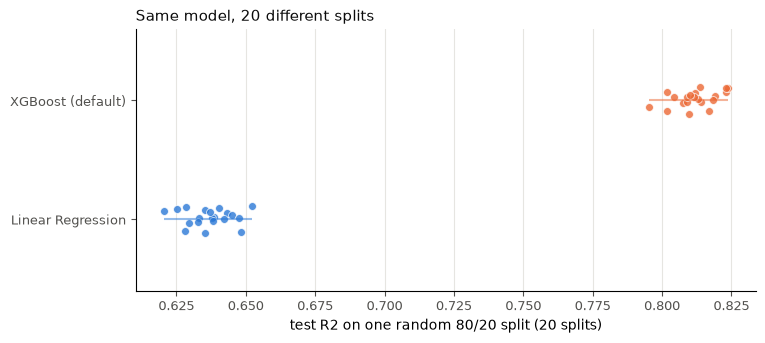

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.4))
rng = np.random.RandomState(0)
for i, (col, color) in enumerate(zip(splits.columns, [BLUE, ORANGE])):
    ax.scatter(splits[col], i + rng.uniform(-0.12, 0.12, len(splits)), s=32, color=color, alpha=0.8, edgecolor="white", linewidth=0.6)
    ax.hlines(i, splits[col].min(), splits[col].max(), color=color, linewidth=1.5, alpha=0.5)
ax.set_yticks([0, 1]); ax.set_yticklabels([c.replace(" R2", "") for c in splits.columns]); ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("test R2 on one random 80/20 split (20 splits)")
ax.set_title("Same model, 20 different splits", loc="left", fontsize=11, color=INK)
style(ax); ax.grid(axis="y", visible=False)
plt.show()

**អានលទ្ធផល:** Linear Regression ដដែលបាន test R² ចាប់ពី **0.621 ដល់ 0.652** (std 0.008) ហើយ XGBoost ចាប់ពី **0.795 ដល់ 0.824** (std 0.008) អាស្រ័យលើ split ចៃដន្យ។ ភាពខុសគ្នាក្នុង model តែមួយគឺប្រហែល 0.03។
- **ប្រៀបធៀបជាមួយ Titanic:** Logistic Regression ដែលមាន 179 test rows បានពិន្ទុ 0.777–0.872 (ជួរ 0.095)។ ត្រង់នេះ test set មាន **3,887 rows** ដូច្នេះ noise តូចជាងប្រហែល 3 ដង (ជួរ ≈ 0.03)។
  Data ធំជាងធ្វើឲ្យ split តែមួយ **ជឿជាក់ជាង** ប៉ុន្តែនៅតែមិនល្អឥតខ្ចោះ។
- **ភាពខុសគ្នារវាង models** (XGBoost ទល់ Linear = 0.17 R²) ធំជាង noise នៃ split (0.03) ច្រើនដង ដូច្នេះការសន្និដ្ឋានថា XGBoost ល្អជាង Linear គឺគួរឲ្យទុកចិត្ត។
  ប៉ុន្តែភាពខុសគ្នា **តូចៗ** (ឧ. 0.01 រវាង models ពីរ) នឹងនៅក្នុង noise ដូច្នេះត្រូវការ Cross-Validation ដើម្បីសន្និដ្ឋាន។

## 3. Hold out the final test set
ចាប់ពីពេលនេះ **test set ត្រូវទុកចាក់សោ**។ ទាំងអស់ដែលនៅសល់ (CV, tuning, ការជ្រើស model) ប្រើ `X_train` តែប៉ុណ្ណោះ។ Split ដូចក្នុង Lessons 2–7 (`random_state=42`)។

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)
X_train.shape, X_test.shape

((15546, 8), (3887, 8))

## 4. Random KFold vs region-aware GroupKFold
ក្នុង Titanic ត្រូវប្រើ `StratifiedKFold` ដើម្បីរក្សាសមាមាត្រ classes។ Regression គ្មាន classes ទេ ដូច្នេះប្រើ `KFold(shuffle=True)` ជាធម្មតា។
ប៉ុន្តែ data នេះមាន **ទីតាំង**: សង្កាត់ជិតគ្នាមានតម្លៃស្រដៀងគ្នា។ ក្នុង `KFold` ចៃដន្យ សង្កាត់ជិតខាងអាចស្ថិតក្នុង train និង validation ទាំងពីរ ដែលអាចធ្វើឲ្យពិន្ទុ **សុទិដ្ឋិនិយម**
ប្រសិនបើយើងចង់ប្រើ model ក្នុង **តំបន់ថ្មី**។ `GroupKFold` ដាក់សង្កាត់ក្នុង **តំបន់ (ក្រឡា 1° × 1°)** តែមួយ ទៅ fold តែមួយ ដូច្នេះ validation គឺជាតំបន់ដែល model មិនធ្លាប់ឃើញ។

In [5]:
groups = (X_train["Latitude"] // 1).astype(int).astype(str) + "_" + (X_train["Longitude"] // 1).astype(int).astype(str)
rows = []
for name, model in [("Linear Regression", LinearRegression()), ("XGBoost (default)", XGBRegressor(random_state=42, n_jobs=-1))]:
    rand = cross_val_score(model, X_train, y_train, cv=cv5, scoring="r2")
    region = cross_val_score(model, X_train, y_train, cv=GroupKFold(n_splits=5), groups=groups, scoring="r2")
    rows.append({"model": name, "random KFold: mean R2": rand.mean(), "random KFold: std": rand.std(),
                 "GroupKFold (regions): mean R2": region.mean(), "GroupKFold: std": region.std()})
{"number of 1-degree regions": int(groups.nunique())}, pd.DataFrame(rows).set_index("model").round(4)

({'number of 1-degree regions': 53},
                    random KFold: mean R2  random KFold: std  \
 model                                                         
 Linear Regression                 0.6335             0.0134   
 XGBoost (default)                 0.8066             0.0091   
 
                    GroupKFold (regions): mean R2  GroupKFold: std  
 model                                                              
 Linear Regression                         0.6025           0.0690  
 XGBoost (default)                         0.6260           0.0376  )

**អានលទ្ធផល:** នេះជាលទ្ធផលសំខាន់បំផុតនៃ notebook នេះ។ (53 តំបន់ 1° × 1°)

| Model | random `KFold` R² | `GroupKFold` (តំបន់មិនធ្លាប់ឃើញ) R² | ធ្លាក់ |
|---|---|---|---|
| Linear Regression | 0.634 ± 0.013 | 0.603 ± 0.069 | −0.03 |
| XGBoost (default) | 0.807 ± 0.009 | 0.626 ± 0.038 | **−0.18** |

- **Linear Regression ស្ទើរតែមិនប្រែប្រួល** (−0.03) ព្រោះវាប្រើតែ coefficients ទូទៅ ហើយមិន "ចងចាំ" សង្កាត់ជាក់លាក់។
- **XGBoost ធ្លាក់ 0.18**: ការទទួលបានល្អក្នុង random `KFold` មួយផ្នែកធំមកពី **ការចងចាំភូមិសាស្ត្រ**: សង្កាត់ជិតខាង (ក្នុង train) មានតម្លៃស្រដៀងគ្នា ហើយ model ប្រើ `Latitude`/`Longitude` ដើម្បី "រកឃើញ" ពួកវា។
  ពេលតំបន់ទាំងមូលត្រូវបានទុកចោល model លែងមានជិតខាងទាំងនោះ ហើយជម្រៅរបស់វាធ្លាក់ទៅជិត Linear (0.626 ទល់ 0.603)។
- **ការបកស្រាយ:** ពិន្ទុក្នុង Lessons 2–7 (R² 0.83) ត្រូវនឹងសំណួរ "**តើ model ទាយសង្កាត់ថ្មីក្នុងតំបន់ដែលមាន data រួចហើយបានល្អប៉ុនណា?**" ដែលជាករណីប្រើជាក់ស្តែងជាច្រើន (ឧ. សង្កាត់ថ្មីក្នុងទីក្រុងដែលស្គាល់)។
  ប៉ុន្តែវា **មិនធានា** ដំណើរការដូចគ្នាសម្រាប់ **តំបន់ដែលមិនធ្លាប់ឃើញទាំងស្រុង** ទេ។ យើងនឹងសរសេរដែនកំណត់នេះក្នុង README។
- ចំណាំ: `GroupKFold` ជាការសាកល្បងតឹងរ៉ឹងបំផុត (ក្រឡា 1° ≈ 100 km; ដោយមានតែ 53 តំបន់ std ខ្ពស់: 0.038–0.069)។ ការពិតស្ថិតនៅចន្លោះ random `KFold` និង `GroupKFold`។
  ក្នុង notebooks ដែលនៅសល់ យើងប្រើ `KFold(shuffle=True)` (ដូចក្នុង Titanic) ព្រោះគោលដៅរបស់យើងគឺប្រៀបធៀប models ទៅវិញទៅមក ដែលចំណាត់ថ្នាក់ដូចគ្នាទាំងពីរ (XGBoost ≥ Linear) ប៉ុន្តែយើងត្រូវដឹងពីដែនកំណត់នេះ។

## 5. Leakage demo: preprocessing outside vs inside the CV folds
**ខុស:** scale **training set ទាំងមូល** មុន CV (scaler ឃើញ validation rows នៃ fold នីមួយៗ)។ **ត្រូវ:** ដាក់ scaler ក្នុង `Pipeline` ដើម្បីឲ្យវា `fit` ឡើងវិញលើ training folds តែប៉ុណ្ណោះ។
សាកល្បងជាមួយ KNN (k=15) ព្រោះវាត្រូវការ scaling។

In [6]:
knn = KNeighborsRegressor(n_neighbors=15)
X_scaled_all = StandardScaler().fit_transform(X_train)     # WRONG: scaler fitted on ALL training rows before CV
outside = cross_val_score(knn, X_scaled_all, y_train, cv=cv5, scoring="r2")
inside = cross_val_score(Pipeline([("scaler", StandardScaler()), ("knn", knn)]), X_train, y_train, cv=cv5, scoring="r2")
pd.DataFrame({"scaler outside CV (wrong)": outside, "scaler inside Pipeline (right)": inside},
             index=[f"fold {i}" for i in range(1, 6)]).agg(["mean", "std"]).round(5)

,scaler outside CV (wrong),scaler inside Pipeline (right)
mean,0.69213,0.69157
std,0.01751,0.01630


**អានលទ្ធផល:** មធ្យម R² ដោយ scale **ខាងក្រៅ** CV (ខុស) = 0.6921 ទល់ ខាងក្នុង `Pipeline` (ត្រូវ) = 0.6916 → ភាពខុសគ្នាត្រឹម **0.0006**។ ដូចក្នុង Titanic ការ leak នេះ **តូចណាស់** ព្រោះ `StandardScaler` រៀនតែ mean/std (ពីរលេខក្នុងមួយ feature) ពី 15,546 rows ដែលស្ទើរតែមិនប្រែពេលដក validation fold ចេញ។
- **ប៉ុន្តែនេះមិនមែនជាលេសសម្រាប់ធ្វើខុសទេ។** Leakage កើនឡើងពេល: preprocessing ប្រើ **target** (ឧ. target encoding), data តូច, ឬ preprocessing ស្មុគស្មាញ (feature selection, PCA)។ `Pipeline` ត្រឹមត្រូវជានិច្ច ហើយមិនត្រូវការគិត។

## 6. Fair model comparison with repeated CV (training set only)
`RepeatedKFold(n_splits=5, n_repeats=2)` = 10 validation scores ក្នុងមួយ model (2 ការបំបែកផ្សេងគ្នា)។ Models ទាំងអស់ត្រូវបាន train លើ rows ដូចគ្នាគ្រប់ fold ដូច្នេះការប្រៀបធៀបយុត្តិធម៌។
Scalers ស្ថិតក្នុង `Pipeline`។ Hyperparameters មកពី Lessons 3–7 (XGBoost tuned ប្រើ settings ពី `RandomizedSearchCV` ក្នុង Lesson 7)។

In [7]:
BEST_XGB = dict(n_estimators=863, learning_rate=0.0477, max_depth=7, min_child_weight=4,
                subsample=0.6226, colsample_bytree=0.64, reg_lambda=3.5139)   # from Lesson 7

def scaled(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

models = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": scaled(LinearRegression()),
    "KNN (k=15)": scaled(KNeighborsRegressor(n_neighbors=15)),
    "Tree (max_depth=9)": DecisionTreeRegressor(max_depth=9, random_state=42),
    "Random Forest (100 trees)": RandomForestRegressor(n_estimators=100, max_features=0.5, random_state=42),
    "SVR (C=3, gamma=0.3)": scaled(SVR(C=3, gamma=0.3)),
    "XGBoost (default)": XGBRegressor(random_state=42, n_jobs=1),
    "XGBoost (tuned, Lesson 7)": XGBRegressor(random_state=42, n_jobs=1, **BEST_XGB),
}
cv_rep = RepeatedKFold(n_splits=5, n_repeats=2, random_state=42)
scoring = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}

rows = {}
for name, model in models.items():
    r = cross_validate(model, X_train, y_train, cv=cv_rep, scoring=scoring, return_train_score=True, n_jobs=-1)
    rows[name] = {"RMSE mean": -r["test_rmse"].mean(), "RMSE std": r["test_rmse"].std(),
                  "MAE mean": -r["test_mae"].mean(), "R2 mean": r["test_r2"].mean(), "R2 std": r["test_r2"].std(),
                  "train R2": r["train_r2"].mean()}
cv_table = pd.DataFrame(rows).T.sort_values("RMSE mean")
cv_table.round(4)

,RMSE mean,RMSE std,MAE mean,R2 mean,R2 std,train R2
"XGBoost (tuned, Lesson 7)",0.4021,0.0088,0.2701,0.8282,0.0088,0.9719
XGBoost (default),0.4256,0.0069,0.2894,0.8077,0.0079,0.9448
Random Forest (100 trees),0.4508,0.0081,0.3064,0.7842,0.0086,0.9696
"SVR (C=3, gamma=0.3)",0.4877,0.0073,0.3336,0.7475,0.0094,0.8201
KNN (k=15),0.5391,0.0091,0.3854,0.6914,0.0118,0.7318
Tree (max_depth=9),0.5792,0.0114,0.3995,0.6438,0.0160,0.7747
Linear Regression,0.5874,0.0062,0.4384,0.6337,0.0105,0.6345
Baseline (mean),0.9710,0.0101,0.7786,-0.0006,0.0005,0.0000


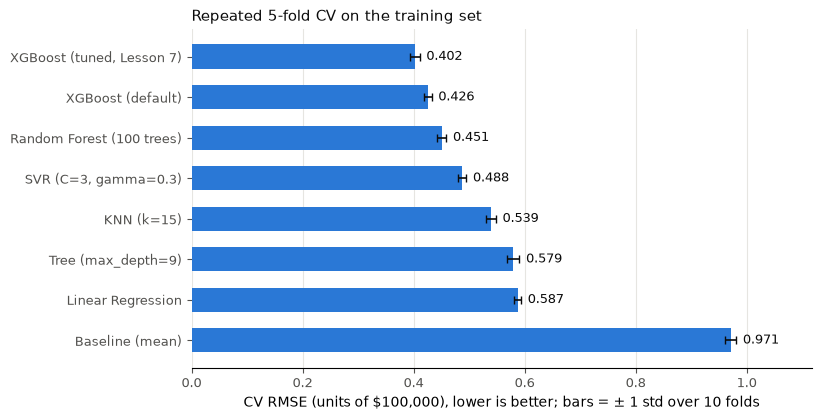

In [8]:
plot_data = cv_table.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(plot_data.index, plot_data["RMSE mean"], xerr=plot_data["RMSE std"], color=BLUE, height=0.6,
        error_kw={"ecolor": INK, "elinewidth": 1.2, "capsize": 3})
for y_pos, (m, s) in enumerate(zip(plot_data["RMSE mean"], plot_data["RMSE std"])):
    ax.text(m + s + 0.012, y_pos, f"{m:.3f}", va="center", fontsize=9, color=INK)
ax.set_xlabel("CV RMSE (units of $100,000), lower is better; bars = ± 1 std over 10 folds")
ax.set_title("Repeated 5-fold CV on the training set", loc="left", fontsize=11, color=INK)
ax.set_xlim(0, plot_data["RMSE mean"].max() * 1.15)
ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(colors=MUTED, labelsize=9)
plt.show()

**អានលទ្ធផល** (RMSE ទាប = ល្អជាង; ± គឺ std លើ 10 folds):

| Model | CV RMSE | CV R² | train R² |
|---|---|---|---|
| **XGBoost (tuned)** | **0.402 ± 0.009** | 0.828 | 0.972 |
| XGBoost (default) | 0.426 ± 0.007 | 0.808 | 0.945 |
| Random Forest (100 trees) | 0.451 ± 0.008 | 0.784 | 0.970 |
| SVR | 0.488 ± 0.007 | 0.748 | 0.820 |
| KNN (k=15) | 0.539 ± 0.009 | 0.691 | 0.732 |
| Tree (max_depth=9) | 0.579 ± 0.011 | 0.644 | 0.775 |
| Linear Regression | 0.587 ± 0.006 | 0.634 | 0.635 |
| Baseline | 0.971 ± 0.010 | 0.000 | 0.000 |

- **ចំណាត់ថ្នាក់** ដូចគ្នានឹងលើ test set ក្នុង Lessons 2–7 (boosting > forest > SVR > KNN > tree > linear)។ **Std តូច** (0.006–0.011) បើធៀបនឹងគម្លាតរវាងក្រុម models ដូច្នេះចំណាត់ថ្នាក់គួរឲ្យទុកចិត្ត។
- **XGBoost tuned ល្អជាង default** 0.024 ដែលស្មើប្រហែល **2.7 std** → ភាពខុសគ្នាពិតប្រាកដ (ក្នុង Titanic ភាពខុសគ្នារវាង models តូចជាង noise)។
- **គម្លាត train − CV R²** (សញ្ញា overfit): Linear 0.001 (គ្មាន), KNN 0.04, SVR 0.07, tree 0.13, XGBoost tuned 0.14, forest 0.19។ Forest overfit ច្រើនបំផុតតាម train score ប៉ុន្តែ CV score នៅតែខ្ពស់ជាង model ទាំង 5 ខាងក្រោម។ **CV score ទើបជាអ្វីដែលសំខាន់ មិនមែន train score ទេ។**
- ⚠️ CV score របស់ XGBoost tuned ស្ថិតក្នុងភាពសុទិដ្ឋិនិយមតិចតួច ព្រោះ hyperparameters របស់វាត្រូវបានជ្រើសដោយ CV លើ training set ដូចគ្នាក្នុង Lesson 7 (ការជ្រើសរើស winner)។

## 7. Bias/variance with learning curves
**Learning curve**: ទាំង train និង validation score ពេលចំនួន training rows កើនឡើង (5-fold CV)។ ប្រៀបធៀប model **សាមញ្ញ** (Linear Regression: ជាធម្មតា underfit)
និង model **ដែលអាចបត់បែនបាន** (XGBoost default: ជាធម្មតាមាន variance ខ្ពស់ជាង)។

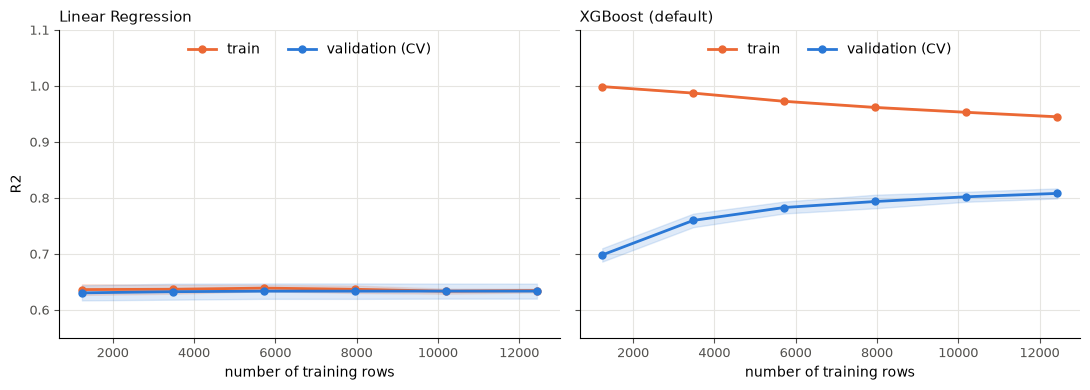

In [9]:
sizes = np.linspace(0.1, 1.0, 6)
curves = {}
for name, model in [("Linear Regression", scaled(LinearRegression())), ("XGBoost (default)", XGBRegressor(random_state=42, n_jobs=1))]:
    ts, tr, va = learning_curve(model, X_train, y_train, train_sizes=sizes, cv=cv5, scoring="r2", n_jobs=-1)
    curves[name] = (ts, tr, va)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, (ts, tr, va)) in zip(axes, curves.items()):
    for scores, color, label in [(tr, ORANGE, "train"), (va, BLUE, "validation (CV)")]:
        ax.plot(ts, scores.mean(axis=1), color=color, linewidth=2, marker="o", markersize=5, label=label)
        ax.fill_between(ts, scores.mean(axis=1) - scores.std(axis=1), scores.mean(axis=1) + scores.std(axis=1), color=color, alpha=0.15)
    ax.set_xlabel("number of training rows"); ax.set_title(name, loc="left", fontsize=11, color=INK)
    ax.set_ylim(0.55, 1.1); ax.legend(frameon=False, loc="upper center", ncol=2); style(ax)
axes[0].set_ylabel("R2")
fig.tight_layout()
plt.show()

In [10]:
pd.DataFrame({f"{name}: {kind}": scores.mean(axis=1) for name, (ts, tr, va) in curves.items()
              for kind, scores in [("train R2", tr), ("validation R2", va)]},
             index=curves["Linear Regression"][0]).round(3)

,Linear Regression: train R2,Linear Regression: validation R2,XGBoost (default): train R2,XGBoost (default): validation R2
1243,0.636,0.630,0.999,0.698
3482,0.637,0.633,0.987,0.760
5720,0.639,0.633,0.973,0.783
7959,0.637,0.633,0.962,0.794
10197,0.633,0.634,0.953,0.802
12436,0.635,0.634,0.945,0.808


**អានក្រាហ្វ:**
- **Linear Regression (bias ខ្ពស់ = underfitting):** train R² និង validation R² **ស្ទើរតែស្មើគ្នា** (≈ 0.635) ហើយ **រាបស្មើ** ទោះ rows ច្រើនប៉ុនណា។
  ការបន្ថែម data **មិនជួយទេ**: model សាមញ្ញពេក។ ដើម្បីប្រសើរឡើងត្រូវការ model ស្មុគស្មាញជាង ឬ features ថ្មី (ពិចារណា notebook 09)។
- **XGBoost default (variance ខ្ពស់ = overfitting):** train R² ខ្ពស់ (0.999 → 0.945) ហើយ validation R² ទាបជាងច្រើន (0.698 → 0.808): **គម្លាតធំ 0.14 នៅចុងបញ្ចប់**។
  ប៉ុន្តែ validation R² **នៅតែកើនឡើង** ពេល rows កើន (0.802 → 0.808 ពី 10,197 ទៅ 12,436 rows) ដូច្នេះ **data បន្ថែមនឹងជួយ**។ គម្លាតបិទបន្តិចម្តងៗពេល data កើន។
- **សង្ខេប:** Linear = bias (រាបស្មើ, គ្មានគម្លាត); XGBoost = variance (គម្លាតធំ, validation នៅកើន)។ ប្រភេទបញ្ហាខុសគ្នា ត្រូវការដំណោះស្រាយខុសគ្នា (model ស្មុគស្មាញជាង ទល់ data/regularization ច្រើនជាង)។

## 8. Validation curve: max_depth of a Decision Tree (by CV)
ក្នុង Lesson 4 យើងជ្រើស `max_depth` ដោយ **test set**។ ឥឡូវនេះធ្វើវាឲ្យត្រឹមត្រូវ: **validation curve** ដោយ 5-fold CV លើ training set។

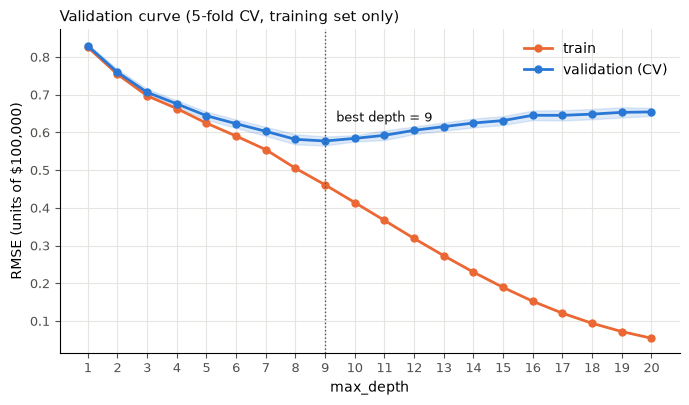

9

In [11]:
depths = list(range(1, 21))
train_scores, val_scores = validation_curve(DecisionTreeRegressor(random_state=42), X_train, y_train,
                                            param_name="max_depth", param_range=depths, cv=cv5,
                                            scoring="neg_root_mean_squared_error", n_jobs=-1)
vc = pd.DataFrame({"train RMSE": -train_scores.mean(axis=1), "CV RMSE": -val_scores.mean(axis=1),
                   "CV std": val_scores.std(axis=1)}, index=pd.Index(depths, name="max_depth"))
best_depth_cv = int(vc["CV RMSE"].idxmin())

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(vc.index, vc["train RMSE"], color=ORANGE, linewidth=2, marker="o", markersize=5, label="train")
ax.plot(vc.index, vc["CV RMSE"], color=BLUE, linewidth=2, marker="o", markersize=5, label="validation (CV)")
ax.fill_between(vc.index, vc["CV RMSE"] - vc["CV std"], vc["CV RMSE"] + vc["CV std"], color=BLUE, alpha=0.15)
ax.axvline(best_depth_cv, color=MUTED, linewidth=1, linestyle=":")
ax.annotate(f"best depth = {best_depth_cv}", (best_depth_cv, vc["CV RMSE"].min()), xytext=(8, 14),
            textcoords="offset points", color=INK, fontsize=9)
ax.set_xticks(vc.index); ax.set_xlabel("max_depth"); ax.set_ylabel("RMSE (units of $100,000)")
ax.set_title("Validation curve (5-fold CV, training set only)", loc="left", fontsize=11, color=INK)
ax.legend(frameon=False); style(ax)
plt.show()
best_depth_cv

In [12]:
vc.loc[[1, 3, 5, 7, 8, 9, 10, 12, 15, 20]].round(4).T

max_depth,1,3,5,7,8,9,10,12,15,20
train RMSE,0.8259,0.6973,0.6247,0.5545,0.5051,0.4612,0.4142,0.3190,0.1893,0.0547
CV RMSE,0.8297,0.7064,0.6444,0.6030,0.5817,0.5774,0.5843,0.6057,0.6315,0.6545
CV std,0.0043,0.0089,0.0107,0.0119,0.0134,0.0118,0.0082,0.0100,0.0116,0.0107


**អានក្រាហ្វ:**
- **Depth 1–5:** train និង CV RMSE ខ្ពស់ ហើយជិតគ្នា (depth 1: 0.826 និង 0.830) → **underfitting**។
- **Depth 9** មាន CV RMSE ទាបបំផុត (**0.5774**) ហើយ depth 8 ស្ទើរតែដូចគ្នា (0.5817)។ បន្ទាប់ពីនោះ train RMSE ធ្លាក់ទៅ 0.055 (depth 20) ខណៈ CV RMSE **កើនឡើង** ដល់ 0.6545 → **overfitting**។
- **ដូចគ្នានឹង Lesson 4** (ដែលជ្រើស depth 9 ដោយ test set): ត្រង់នេះ CV លើ training set តែប៉ុណ្ណោះក៏ជ្រើស depth 9 ដូចគ្នា។ នេះបញ្ជាក់ថា ការព្រមាន leakage ស្រាលរបស់យើងមិនបានបង្កបញ្ហាត្រង់នេះទេ
  (ព្រោះខ្សែកោងរាបស្មើ ជុំវិញកំពូល) ប៉ុន្តែវិធីនេះត្រឹមត្រូវជានិច្ច ដោយមិនត្រូវមើល test set។
- Band (± std) រវាង depth 8–10 ត្រួតស៊ីគ្នា: មិនអាចនិយាយថា depth 9 ល្អជាង 8 ឬ 10 ទេ។ ជ្រើស depth ណាមួយក្នុងចន្លោះ 8–10 នឹងល្អស្មើគ្នា។

## 9. GridSearchCV vs RandomizedSearchCV (Random Forest)
ចន្លោះ 3 hyperparameters: `max_features` (4 តម្លៃ) × `min_samples_leaf` (4) × `max_depth` (3) = **48 បន្សំ**។ Grid សាកល្បងទាំង 48; Random សាកល្បង 10។ ទាំងពីរប្រើ 3-fold CV លើ training set។
(ចំនួនវិនាទីអាស្រ័យលើកុំព្យូទ័ររបស់អ្នក; ប្រៀបធៀប **សមាមាត្រ**។)

In [13]:
space = {"max_features": [0.33, 0.5, 0.75, 1.0], "min_samples_leaf": [1, 2, 3, 5], "max_depth": [None, 12, 20]}
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=1)
cv3 = KFold(n_splits=3, shuffle=True, random_state=42)

results = {}
for name, search in [
    ("GridSearchCV", GridSearchCV(rf, space, cv=cv3, scoring="neg_root_mean_squared_error", n_jobs=-1)),
    ("RandomizedSearchCV (n_iter=10)", RandomizedSearchCV(rf, space, n_iter=10, cv=cv3, scoring="neg_root_mean_squared_error",
                                                          random_state=42, n_jobs=-1)),
]:
    start = time.perf_counter()
    search.fit(X_train, y_train)
    results[name] = {"combinations tried": len(search.cv_results_["params"]), "fits (x3 folds)": len(search.cv_results_["params"]) * 3,
                     "seconds": time.perf_counter() - start, "best CV RMSE": -search.best_score_,
                     "best params": str(search.best_params_)}
pd.DataFrame(results).T

,combinations tried,fits (x3 folds),seconds,best CV RMSE,best params
GridSearchCV,48,144,60.522928,0.456769,"{'max_depth': 20, 'max_features': 0.5, 'min_sa..."
RandomizedSearchCV (n_iter=10),10,30,16.250586,0.457561,"{'min_samples_leaf': 1, 'max_features': 0.5, '..."


**អានលទ្ធផល:**
- **Grid** សាកល្បង 48 បន្សំ (144 fits), **Random** សាកល្បង 10 បន្សំ (30 fits)។ Random ប្រើពេល **តិចជាងប្រហែល 4 ដង** (ក្នុង run នេះ ≈ 17 វិនាទី ទល់ 61 វិនាទី)។
- **ពិន្ទុល្អបំផុតស្ទើរតែដូចគ្នា:** CV RMSE 0.4568 (Grid) ទល់ 0.4576 (Random) ភាពខុសគ្នា 0.0008 គឺតូចជាង std ក្នុងចន្លោះ folds ជាច្រើនដង ដូច្នេះមិនមែនជាភាពខុសគ្នាពិតប្រាកដទេ។
- **ហេតុអ្វី Random ជាធម្មតាល្អគ្រប់គ្រាន់:** hyperparameters ជាច្រើនមិនសំខាន់ (ឧ. Lesson 5 បានបង្ហាញថា `min_samples_leaf` និង `max_features` មានឥទ្ធិពលតូច) ហើយតំបន់ល្អមានទំហំធំ ដូច្នេះបន្សំចៃដន្យមួយចំនួនតូចស្ទើរតែប៉ះវា។
  បើមាន hyperparameters ច្រើន (7 ក្នុង Lesson 7) Grid កើនឡើងជាមួយនិទស្សន្ត: ដូច្នេះ Random ជា **ជម្រើសលំនាំដើម** សម្រាប់ model ស្មុគស្មាញ។ Grid សមសម្រាប់ចន្លោះតូច (1–2 hyperparameters)។
- ⚠️ ទាំងពីរពិន្ទុល្អបំផុតគឺ CV score ដែលត្រូវបានជ្រើសពីបន្សំជាច្រើន → សុទិដ្ឋិនិយមតិចតួច។

## 10. Final: choose ONE model by CV, then touch the test set ONCE
**ច្បាប់:** ជ្រើស model ដែលមាន CV RMSE ទាបបំផុត។ បើ models ជាច្រើនស្ថិតក្នុង **1 std** នៃអ្នកល្អបំផុត ត្រូវពិចារណា model សាមញ្ញជាង (ពិន្ទុនៅក្នុង noise)។
ជ្រើសពីតារាងក្នុង Step 6 (មិនប្រើ test set)។

In [14]:
best_name = cv_table["RMSE mean"].idxmin()
within_one_std = cv_table.index[cv_table["RMSE mean"] <= cv_table["RMSE mean"].min() + cv_table.loc[best_name, "RMSE std"]].tolist()
{"best by CV RMSE": best_name, "models within 1 std of the best": within_one_std}

{'best by CV RMSE': 'XGBoost (tuned, Lesson 7)',
 'models within 1 std of the best': ['XGBoost (tuned, Lesson 7)']}

Train model ដែលបានជ្រើសលើ training set ទាំងមូល ហើយវាយតម្លៃ **ម្តងគត់** លើ test set។ ប្រៀបធៀបជាមួយ CV estimate។

In [15]:
final_model = models[best_name].fit(X_train, y_train)
pred = final_model.predict(X_test)
test_rmse = float(np.sqrt(mean_squared_error(y_test, pred)))
pd.DataFrame({
    "CV (training set, repeated 5-fold x2)": {"RMSE": cv_table.loc[best_name, "RMSE mean"], "MAE": cv_table.loc[best_name, "MAE mean"],
                                                "R2": cv_table.loc[best_name, "R2 mean"]},
    "Test set (opened once)": {"RMSE": test_rmse, "MAE": mean_absolute_error(y_test, pred), "R2": r2_score(y_test, pred)},
}).round(4)

,"CV (training set, repeated 5-fold x2)",Test set (opened once)
RMSE,0.4021,0.3992
MAE,0.2701,0.2642
R2,0.8282,0.8336


**អានលទ្ធផល:**
- **Model ដែលបានជ្រើស: XGBoost (tuned)**: CV RMSE ទាបបំផុត ហើយ **គ្មាន model ផ្សេងស្ថិតក្នុង 1 std ទេ** (default ឆ្ងាយ 2.7 std) ដូច្នេះមិនមានមូលហេតុដើម្បីជ្រើស model សាមញ្ញជាងទេ។ (ក្នុង Titanic models ទាំងអស់ស្ថិតក្នុង noise ដូច្នេះ Logistic Regression ឈ្នះដោយភាពសាមញ្ញ ប៉ុន្តែត្រង់នេះ data ធំ ហើយភាពខុសគ្នាពិតប្រាកដ។)
- **CV estimate ទល់ test set (បើកម្តងគត់):**

| Metric | CV (training set) | Test set |
|---|---|---|
| RMSE | 0.4021 ± 0.0088 | **0.3992** |
| MAE | 0.2701 | **0.2642** |
| R² | 0.8282 ± 0.0088 | **0.8336** |

  លទ្ធផល test ស្ថិតក្នុង **1 std** នៃ CV estimate ហើយល្អជាងបន្តិច (model ចុងក្រោយ train លើ training set ទាំងមូល ចំណែក CV train លើ 80% នៃវា)។ **Cross-Validation បានព្យាករលទ្ធផលប្រឡងយ៉ាងត្រឹមត្រូវ។**
- Test set ត្រូវបានប៉ះ **ម្តង** ក្នុង notebook នេះ។ (Lessons 2–7 បានបើកវាដើម្បីប្រៀបធៀប models ហើយ Lessons 3–4 បានជ្រើស `k` និង `max_depth` ពីវា ដូចបានព្រមានរួចហើយ។)

## Lesson summary
- **Split តែមួយមាន noise**: Linear R² 0.621–0.652, XGBoost 0.795–0.824 លើ 20 splits ចៃដន្យ (std ≈ 0.008)។ ជាមួយ 3,887 test rows noise តូចជាង Titanic (179 rows, ជួរ 0.095) ប្រហែល 3 ដង ប៉ុន្តែនៅមាន។
- **K-fold Cross-Validation** លើ training set ផ្តល់ **mean ± std**។ ប្រើ `RepeatedKFold` ដើម្បីកាត់បន្ថយ noise បន្ថែម។ Regression ប្រើ `KFold(shuffle=True)` ជំនួស `StratifiedKFold`។
- **Data ដែលមានទីតាំង:** random `KFold` ធ្វើឲ្យ XGBoost មើលទៅល្អ (R² 0.807) ប៉ុន្តែ `GroupKFold` តាមតំបន់ ផ្តល់ត្រឹម **0.626** ខណៈ Linear ស្ទើរតែមិនប្រែ (0.634 → 0.603)។ **ពិន្ទុរបស់យើងអនុវត្តចំពោះសង្កាត់ក្នុងតំបន់ដែល model ធ្លាប់ឃើញ មិនមែនតំបន់ថ្មីទាំងស្រុងទេ។**
- **Pipeline ក្នុង CV:** scaler fit ឡើងវិញក្នុងរាល់ fold។ ការ leak ពី scaling ខាងក្រៅ CV តូច (0.0006) ប៉ុន្តែកើនឡើងពេល preprocessing ប្រើ target ឬ data តូច។
- **Repeated CV (10 folds):** XGBoost tuned 0.402 ± 0.009 > XGBoost default 0.426 > Random Forest 0.451 > SVR 0.488 > KNN 0.539 > Tree 0.579 > Linear 0.587 (RMSE)។ ចំណាត់ថ្នាក់ដូចលើ test set។
- **Bias vs variance:** Linear: train ≈ validation ≈ 0.635, រាបស្មើ → bias (data បន្ថែមមិនជួយ)។ XGBoost: គម្លាត 0.14 ហើយ validation នៅកើន → variance (data បន្ថែមជួយ)។
- **Validation curve** (CV, training set): `max_depth` ល្អបំផុតគឺ 9 (CV RMSE 0.577) ដូច Lesson 4 ប៉ុន្តែត្រឹមត្រូវដោយមិនប្រើ test set។
- **Grid ទល់ Random:** Random (10 បន្សំ) ស្ទើរតែល្អស្មើ Grid (48 បន្សំ): 0.4576 ទល់ 0.4568 ក្នុងពេលតិចជាង ≈ 4 ដង។
- **ជ្រើស model តែមួយដោយ CV (XGBoost tuned) ហើយបើក test set តែម្តង**: test RMSE 0.399 / MAE 0.264 / R² 0.834 ស្ថិតក្នុង 1 std នៃ CV (0.402 ± 0.009)។
- Lesson 9 ប្រមូលអ្វីៗទាំងអស់ចូលក្នុង `Pipeline` តែមួយដែលអាចរក្សាទុក ហើយវាស់ថា Feature Engineering ជួយឬអត់។

### Leakage checklist (Lessons 1–8)

1. ដក features ដែលជា target ក្នុងទម្រង់ផ្សេង ឬមិនអាចដឹងពេលទាយ (Titanic: `alive`; California: គ្មាន)។
2. ដក rows ដែល label ខុសដោយ **ច្បាប់ថេរ** (cap `MedHouseVal >= 5.0`) មិនមែនដោយ statistics ដែលរៀនពី data។
3. Split មុន; fit imputers, scalers និង encoders លើ training set តែប៉ុណ្ណោះ។
4. ដាក់ preprocessing ក្នុង `Pipeline` ដើម្បីឲ្យវា fit ឡើងវិញក្នុងរាល់ CV fold។
5. កុំជ្រើស model ឬ hyperparameters ដោយ test set; ប្រើ CV, OOB ឬ validation set។ (Lessons 3–4 បានធ្វើបែបនេះសម្រាប់ការបង្ហាញ ហើយយើងបានព្រមានរួចហើយ។)
6. Early stopping ប្រើ validation set ដែលកាត់ពី training ហើយមិនមែន test set។
7. បើ data មានទីតាំង ឬពេលវេលា ពិចារណា `GroupKFold`/`TimeSeriesSplit` ជំនួស `KFold` ចៃដន្យ។
8. វាយតម្លៃ model ចុងក្រោយលើ test set **ម្តងគត់**។
9. ពិន្ទុ CV របស់ model ដែលបាន tune ស្ថិតក្នុងភាពសុទិដ្ឋិនិយមតិចតួច។